# Semana 6 - Regresión logística vs. SVM
## Predicción de fallas en máquinas industriales

**Alumno:** Juan Pablo Monllor

**Problema:** a partir de las condiciones de trabajo de una máquina (temperaturas, velocidad, torque, desgaste y tipo de producto), predecir si va a fallar. Es una clasificación binaria: 0 = sin falla, 1 = falla.

**Modelos:** regresión logística y SVM con kernel RBF.

**Criterio:** no detectar una falla real es el error más grave, por eso se prioriza el recall de la clase "Falla", sin descuidar la precisión.

## 1. Datos

**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI Machine Learning Repository, licencia CC BY 4.0). Es un dataset sintético que imita datos reales de mantenimiento predictivo: 10.000 registros, uno por cada proceso de la máquina.

Fuente: https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

In [17]:
# Importamos las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargamos el dataset
df = pd.read_csv("../datasets/ai4i2020.csv", encoding="utf-8-sig")

# Mostramos las primeras filas
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [18]:
# Dimensiones, valores faltantes y duplicados
print("Dimensiones del dataset:", df.shape)
print("Valores faltantes:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

Dimensiones del dataset: (10000, 14)
Valores faltantes: 0
Filas duplicadas: 0


### Variables

- **Predictoras (6):** tipo de producto (categórica: L, M, H), temperatura del aire, temperatura del proceso, velocidad de giro, torque y desgaste de la herramienta.
- **Objetivo:** `Machine failure` (1 = falla).
- **Se excluyen:** `UDI` y `Product ID`, que son identificadores, y `TWF`, `HDF`, `PWF`, `OSF` y `RNF`, que indican el tipo de falla. Esas cinco solo se conocen después de que la máquina falló: usarlas sería una fuga de datos.

In [19]:
# Armamos una copia solo con las columnas que vamos a usar
datos = df[[
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]].copy()

# Renombramos las columnas
datos.columns = ["tipo", "temp_aire", "temp_proceso", "velocidad", "torque", "desgaste", "falla"]

# Listas de variables según su tipo
variables_numericas = ["temp_aire", "temp_proceso", "velocidad", "torque", "desgaste"]
variables_categoricas = ["tipo"]

datos.head()

,tipo,temp_aire,temp_proceso,velocidad,torque,desgaste,falla
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 2. Exploración

In [20]:
# Cantidad de registros por clase
nombres_clases = {0: "Sin falla", 1: "Falla"}
conteo_clases = datos["falla"].value_counts().sort_index()

for clase, cantidad in conteo_clases.items():
    print(f"{nombres_clases[clase]}: {cantidad} registros ({cantidad / len(datos) * 100:.2f}%)")

Sin falla: 9661 registros (96.61%)
Falla: 339 registros (3.39%)


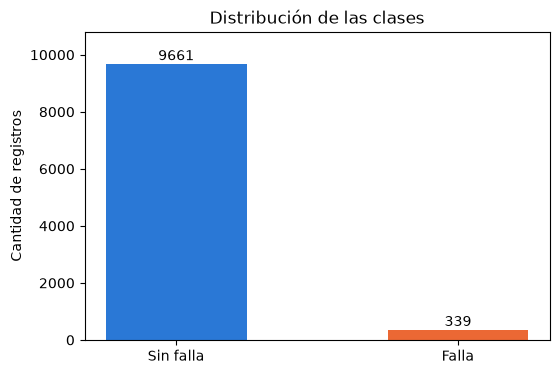

In [21]:
# Colores que se usan en todos los gráficos de clases
color_sin_falla = "#2a78d6"
color_falla = "#eb6834"

# Gráfico de barras con la cantidad de registros por clase
etiquetas = ["Sin falla", "Falla"]
cantidades = [conteo_clases[0], conteo_clases[1]]

plt.figure(figsize=(6, 4))
plt.bar(etiquetas, cantidades, color=[color_sin_falla, color_falla], width=0.5)

plt.title("Distribución de las clases")
plt.ylabel("Cantidad de registros")

# Mostramos la cantidad sobre cada barra
for i, cantidad in enumerate(cantidades):
    plt.text(i, cantidad + 150, str(cantidad), ha="center")

plt.ylim(0, 10800)
plt.show()

**Interpretación:** las clases están muy desbalanceadas: solo el 3,39 % son fallas. Un modelo que respondiera siempre "Sin falla" acertaría el 97 % de las veces sin detectar ninguna falla, así que la exactitud sola no sirve para evaluar.

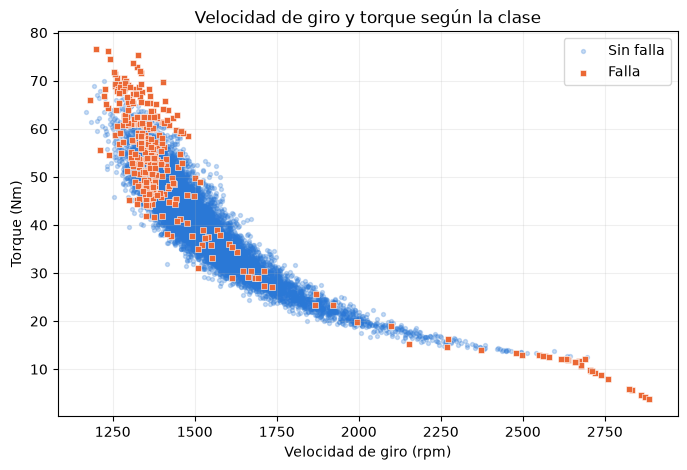

In [22]:
# Separamos los datos por clase
sin_falla = datos[datos["falla"] == 0]
con_falla = datos[datos["falla"] == 1]

# Gráfico de dispersión: velocidad vs torque
plt.figure(figsize=(8, 5))

plt.scatter(sin_falla["velocidad"], sin_falla["torque"],
            label="Sin falla", color=color_sin_falla, alpha=0.25, s=8)
plt.scatter(con_falla["velocidad"], con_falla["torque"],
            label="Falla", color=color_falla, marker="s", s=18,
            edgecolors="white", linewidths=0.4)

plt.title("Velocidad de giro y torque según la clase")
plt.xlabel("Velocidad de giro (rpm)")
plt.ylabel("Torque (Nm)")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

**Interpretación:** la velocidad y el torque están muy relacionados y forman una curva: a mayor velocidad, menor torque. Las fallas se concentran en los dos extremos de esa curva y, arriba a la izquierda, se superponen con máquinas sin falla. Como la zona normal tiene forma curva, una frontera recta y una curva la van a separar de manera distinta.

## 3. Preparación

- `tipo` se convierte en columnas de 0 y 1 (One-Hot Encoding): los modelos reciben 8 columnas de entrada.
- División estratificada: 60 % entrenamiento, 20 % validación (para elegir la configuración de cada modelo) y 20 % prueba (para la comparación final).
- Escalado de las variables numéricas, ajustado solo con entrenamiento. SVM lo necesita porque trabaja con distancias.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Variables predictoras (X) y objetivo (y), con la categórica convertida a columnas de 0 y 1
X = pd.get_dummies(datos[variables_categoricas + variables_numericas], columns=["tipo"], dtype=int)
y = datos["falla"]

# División: 20% prueba y, del resto, 25% validación (queda 60/20/20)
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, random_state=42, stratify=y_resto)

# Escalado: se ajusta solo con entrenamiento y se aplica a los tres conjuntos
escalador = StandardScaler()
X_train_esc, X_val_esc, X_test_esc = X_train.copy(), X_val.copy(), X_test.copy()
X_train_esc[variables_numericas] = escalador.fit_transform(X_train[variables_numericas])
X_val_esc[variables_numericas] = escalador.transform(X_val[variables_numericas])
X_test_esc[variables_numericas] = escalador.transform(X_test[variables_numericas])

print("Columnas de entrada:", X.shape[1])
print("Entrenamiento:", len(X_train), "registros,", y_train.sum(), "fallas")
print("Validación:", len(X_val), "registros,", y_val.sum(), "fallas")
print("Prueba:", len(X_test), "registros,", y_test.sum(), "fallas")

Columnas de entrada: 8
Entrenamiento: 6000 registros, 203 fallas
Validación: 2000 registros, 68 fallas
Prueba: 2000 registros, 68 fallas


## 4. Modelos

### 4.1 Primer intento: parámetros por defecto

In [24]:
# Importamos los modelos y las métricas
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Función que resume las métricas de un modelo
def calcular_metricas(nombre, y_real, y_pred):
    matriz = confusion_matrix(y_real, y_pred)
    return {
        "Modelo": nombre,
        "Fallas detectadas": matriz[1, 1],
        "Falsas alarmas": matriz[0, 1],
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precisión (Falla)": precision_score(y_real, y_pred, zero_division=0),
        "Recall (Falla)": recall_score(y_real, y_pred),
        "F1 (Falla)": f1_score(y_real, y_pred)
    }

# Creamos y entrenamos los modelos con sus parámetros por defecto
logistica_inicial = LogisticRegression(max_iter=1000)
logistica_inicial.fit(X_train_esc, y_train)

svm_inicial = SVC(kernel="rbf")
svm_inicial.fit(X_train_esc, y_train)

# Comparamos los resultados en validación (68 fallas reales)
resultados_iniciales = pd.DataFrame([
    calcular_metricas("Regresión logística", y_val, logistica_inicial.predict(X_val_esc)),
    calcular_metricas("SVM (kernel RBF)", y_val, svm_inicial.predict(X_val_esc))
]).set_index("Modelo")

display(resultados_iniciales.round(3))

,Fallas detectadas,Falsas alarmas,Accuracy,Precisión (Falla),Recall (Falla),F1 (Falla)
Modelo,,,,,,
Regresión logística,13,4,0.970,0.765,0.191,0.306
SVM (kernel RBF),18,2,0.974,0.900,0.265,0.409


**Interpretación:** los dos superan el 96 % de exactitud, pero en validación detectan muy pocas fallas: 13 de 68 la logística y 18 de 68 SVM. Por el desbalance, les conviene responder casi siempre "Sin falla". Para mejorar se ajusta un parámetro en cada modelo y se elige el valor con mejor F1 de la clase "Falla".

### 4.2 Regresión logística: umbral

La logística calcula una probabilidad de falla y, por defecto, predice "Falla" si supera 0,5. Bajar el umbral aumenta el recall a cambio de más falsas alarmas.

In [25]:
# Probabilidad de falla que calcula la regresión logística para cada registro de validación
modelo_logistica = LogisticRegression(max_iter=1000)
modelo_logistica.fit(X_train_esc, y_train)
prob_val = modelo_logistica.predict_proba(X_val_esc)[:, 1]

# Probamos distintos umbrales
umbrales = [0.5, 0.4, 0.3, 0.2, 0.1]
filas = []
for umbral in umbrales:
    pred_val = (prob_val >= umbral).astype(int)
    filas.append(calcular_metricas(umbral, y_val, pred_val))

tabla_umbrales = pd.DataFrame(filas).set_index("Modelo")
tabla_umbrales.index.name = "Umbral"
display(tabla_umbrales.round(3))

# Elegimos el umbral con mejor F1 en validación
umbral_elegido = tabla_umbrales["F1 (Falla)"].idxmax()
print("Umbral elegido:", umbral_elegido)

,Fallas detectadas,Falsas alarmas,Accuracy,Precisión (Falla),Recall (Falla),F1 (Falla)
Umbral,,,,,,
0.5,13,4,0.970,0.765,0.191,0.306
0.4,15,10,0.968,0.600,0.221,0.323
0.3,21,21,0.966,0.500,0.309,0.382
0.2,30,45,0.958,0.400,0.441,0.420
0.1,41,114,0.930,0.265,0.603,0.368


Umbral elegido: 0.2


**Interpretación:** el mejor equilibrio se da con **umbral 0,2**.

### 4.3 SVM: parámetro C

C controla cuánto se penalizan las violaciones del margen: con un C alto, el modelo se esfuerza más por clasificar bien cada registro, incluidas las fallas. Un C más alto no garantiza un mejor modelo, por eso se prueban varios valores. Gamma queda en su valor por defecto.

In [26]:
# Probamos distintos valores de C
filas = []
for c in [1, 10, 100, 1000]:
    svm_prueba = SVC(kernel="rbf", C=c, gamma="scale")
    svm_prueba.fit(X_train_esc, y_train)
    filas.append(calcular_metricas(c, y_val, svm_prueba.predict(X_val_esc)))

tabla_c = pd.DataFrame(filas).set_index("Modelo")
tabla_c.index.name = "C"
display(tabla_c.round(3))

c_elegido = tabla_c["F1 (Falla)"].idxmax()
gamma_elegido = "scale"
print("C elegido:", c_elegido)

,Fallas detectadas,Falsas alarmas,Accuracy,Precisión (Falla),Recall (Falla),F1 (Falla)
C,,,,,,
1,18,2,0.974,0.900,0.265,0.409
10,29,7,0.977,0.806,0.426,0.558
100,36,10,0.979,0.783,0.529,0.632
1000,37,13,0.978,0.740,0.544,0.627


C elegido: 100


**Interpretación:** al subir C, SVM pasa de detectar 18 a 36 fallas en validación, con pocas falsas alarmas. Con C = 1000 ya no mejora. Se elige **C = 100**.

**Configuración final:** regresión logística con umbral 0,2; SVM con kernel RBF, C = 100 y gamma por defecto.

In [27]:
# Importamos el módulo para medir el tiempo de entrenamiento
import time

# Modelo 1: regresión logística (el umbral se aplica al momento de predecir)
modelo_logistica = LogisticRegression(max_iter=1000)

inicio = time.perf_counter()
modelo_logistica.fit(X_train_esc, y_train)
tiempo_logistica = time.perf_counter() - inicio

# Modelo 2: SVM con kernel RBF y los valores de C y gamma elegidos
modelo_svm = SVC(kernel="rbf", C=c_elegido, gamma=gamma_elegido)

inicio = time.perf_counter()
modelo_svm.fit(X_train_esc, y_train)
tiempo_svm = time.perf_counter() - inicio

print("Modelos entrenados correctamente.")
print(f"Tiempo de entrenamiento - Regresión logística: {tiempo_logistica:.3f} segundos")
print(f"Tiempo de entrenamiento - SVM: {tiempo_svm:.3f} segundos")

Modelos entrenados correctamente.
Tiempo de entrenamiento - Regresión logística: 0.042 segundos
Tiempo de entrenamiento - SVM: 0.118 segundos


## 5. Comparación en prueba

Los dos modelos se evalúan sobre los mismos 2.000 registros de prueba (68 fallas reales), que no se usaron para entrenar ni para elegir la configuración.

Matriz de confusión - Regresión logística:
[[1890   42]
 [  34   34]]

Matriz de confusión - SVM:
[[1914   18]
 [  25   43]]


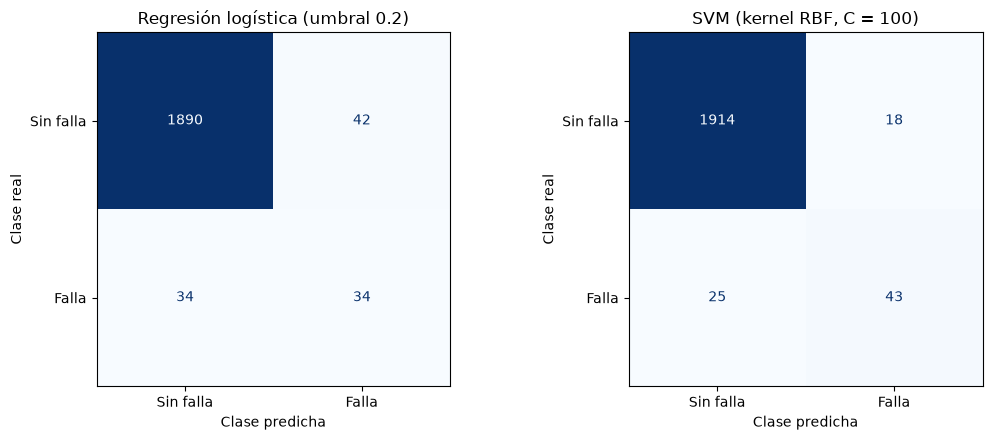

In [28]:
# Importamos la visualización de la matriz de confusión
from sklearn.metrics import ConfusionMatrixDisplay

# Predicciones de cada modelo sobre los datos de prueba
pred_logistica = (modelo_logistica.predict_proba(X_test_esc)[:, 1] >= umbral_elegido).astype(int)
pred_svm = modelo_svm.predict(X_test_esc)

matriz_logistica = confusion_matrix(y_test, pred_logistica)
matriz_svm = confusion_matrix(y_test, pred_svm)

print("Matriz de confusión - Regresión logística:")
print(matriz_logistica)
print("\nMatriz de confusión - SVM:")
print(matriz_svm)

# Visualizamos las dos matrices una al lado de la otra
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay(matriz_logistica, display_labels=["Sin falla", "Falla"]).plot(
    ax=ejes[0], cmap="Blues", colorbar=False)
ejes[0].set_title(f"Regresión logística (umbral {umbral_elegido})")

ConfusionMatrixDisplay(matriz_svm, display_labels=["Sin falla", "Falla"]).plot(
    ax=ejes[1], cmap="Blues", colorbar=False)
ejes[1].set_title(f"SVM (kernel RBF, C = {c_elegido})")

for eje in ejes:
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

In [29]:
# Tabla comparativa de los dos modelos en prueba
resultados = pd.DataFrame([
    calcular_metricas("Regresión logística", y_test, pred_logistica),
    calcular_metricas("SVM (kernel RBF)", y_test, pred_svm)
]).set_index("Modelo")

resultados["Fallas no detectadas"] = [matriz_logistica[1, 0], matriz_svm[1, 0]]

display(resultados.round(3))

,Fallas detectadas,Falsas alarmas,Accuracy,Precisión (Falla),Recall (Falla),F1 (Falla),Fallas no detectadas
Modelo,,,,,,,
Regresión logística,34,42,0.962,0.447,0.500,0.472,34
SVM (kernel RBF),43,18,0.978,0.705,0.632,0.667,25


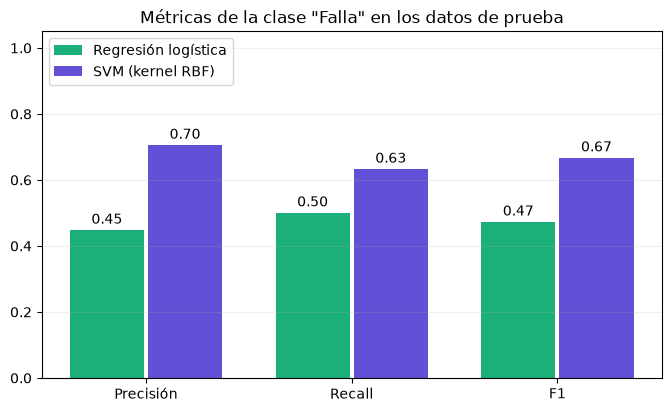

In [30]:
# Gráfico comparativo de las métricas de la clase "Falla"
metricas = ["Precisión (Falla)", "Recall (Falla)", "F1 (Falla)"]
valores_logistica = resultados.loc["Regresión logística", metricas].astype(float).values
valores_svm = resultados.loc["SVM (kernel RBF)", metricas].astype(float).values

posiciones = np.arange(len(metricas))
ancho = 0.36

plt.figure(figsize=(8, 4.5))
barras_log = plt.bar(posiciones - ancho / 2 - 0.01, valores_logistica, ancho,
                     label="Regresión logística", color="#1baf7a")
barras_svm = plt.bar(posiciones + ancho / 2 + 0.01, valores_svm, ancho,
                     label="SVM (kernel RBF)", color="#6250d6")

# Mostramos el valor sobre cada barra
for barras in [barras_log, barras_svm]:
    for barra in barras:
        plt.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.02,
                 f"{barra.get_height():.2f}", ha="center")

plt.title('Métricas de la clase "Falla" en los datos de prueba')
plt.xticks(posiciones, ["Precisión", "Recall", "F1"])
plt.ylim(0, 1.05)
plt.legend(loc="upper left")
plt.grid(axis="y", alpha=0.2)

plt.show()

**Interpretación:** SVM detecta **43 de 68 fallas** (recall 0,63) y la logística **34** (recall 0,50). Además, SVM da **18 falsas alarmas** contra **42** de la logística, por eso su precisión es mucho mayor (0,70 contra 0,45). El F1 resume las dos métricas: 0,67 para SVM y 0,47 para la logística. La exactitud es alta en los dos (98 % y 96 %) y no sirve para diferenciarlos. Aun así, SVM deja pasar una de cada tres fallas.

## 6. Cómo decide cada modelo

**Regresión logística:** aprende un coeficiente para cada columna y los combina en una probabilidad de falla. Los coeficientes se pueden leer:

In [31]:
# Coeficientes aprendidos por la regresión logística
coeficientes = pd.DataFrame({
    "Variable": X_train_esc.columns,
    "Coeficiente": modelo_logistica.coef_[0]
}).sort_values("Coeficiente", ascending=False)

display(coeficientes.round(3).reset_index(drop=True))

,Variable,Coeficiente
0,torque,2.728
1,velocidad,1.970
2,temp_aire,1.572
3,desgaste,0.727
4,tipo_L,0.217
5,tipo_M,0.003
6,tipo_H,-0.210
7,temp_proceso,-0.994


**Interpretación:** el torque es la variable con más peso en el riesgo de falla, seguido por la velocidad y la temperatura del aire. Son asociaciones dentro del modelo, no causas.

**SVM:** no tiene un coeficiente por variable. Compara cada máquina con sus vectores de soporte (los registros de entrenamiento que intervienen en la solución) y, con el kernel RBF, puede armar una frontera curva. Es más flexible, pero mucho menos interpretable.

In [32]:
# Cantidad de vectores de soporte que utiliza el modelo SVM
print("Vectores de soporte por clase (Sin falla, Falla):", modelo_svm.n_support_)
print("Total de vectores de soporte:", modelo_svm.n_support_.sum(), "de", len(X_train_esc), "registros de entrenamiento")

Vectores de soporte por clase (Sin falla, Falla): [193 123]
Total de vectores de soporte: 316 de 6000 registros de entrenamiento


La frontera de SVM queda definida por 316 de los 6.000 registros de entrenamiento.

## Conclusión

| | Regresión logística | SVM (kernel RBF) |
|---|---:|---:|
| Fallas detectadas (de 68) | 34 | 43 |
| Falsas alarmas | 42 | 18 |
| Precisión / Recall / F1 | 0,45 / 0,50 / 0,47 | 0,70 / 0,63 / 0,67 |

| | A favor | En contra |
|---|---|---|
| **Regresión logística** | Se interpreta: los coeficientes muestran qué variables pesan más. Da una probabilidad de falla. Entrena más rápido. | Su frontera es lineal: detecta menos fallas y da más falsas alarmas. |
| **SVM** | Su frontera puede ser curva: detecta más fallas con menos falsas alarmas. | No tiene coeficientes que se puedan leer. Necesita escalado y es más lento con muchos datos. |

**Modelo elegido: SVM**, porque supera a la regresión logística en recall, precisión y F1 de la clase "Falla", que es lo que importa en este problema. Si el objetivo fuera explicar por qué una máquina está en riesgo, convendría la regresión logística.

**Límites:** el dataset es sintético y solo se probaron algunos valores del umbral y de C. Aun con SVM, una de cada tres fallas no se detecta.